# Toolkit financiero: demostración con datos reales

Este notebook recorre las capacidades del toolkit tal como lo usaría un analista, **sin
tocar ningún adaptador concreto**. Todo se pide a los casos de uso que construye
`toolkit.bootstrap` (el *composition root*):

| Caso de uso (puerto inbound) | Se construye con | Para qué |
|---|---|---|
| `DownloadData` | `build_download_service(fuente_precios, fuente_macro)` | Descargar series de precios y macro en lote |
| `ListDocuments` | `build_document_service(fuente)` | Listar documentos regulatorios |
| `StoreSeries` | `build_storage_service(directorio, formato)` | Guardar las series en CSV o Parquet |

La cartera (`Portfolio`), el Monte Carlo y el informe son objetos del dominio que
trabajan con esas series, vengan de la fuente que vengan.

Contenido:

1. Puesta en marcha
2. Acciones e índices en lote (y tolerancia a fallos)
3. El mismo contrato con otras fuentes de mercado
4. Datos adicionales: macro, fiscal, materias primas y fundamentales
5. FRED: última revisión frente a vintage (*look-ahead bias*)
6. Documentos regulatorios
7. Validación de inputs
8. Limpieza y alineación de calendarios
9. Cartera: métricas y gráficos
10. Monte Carlo
11. Informe de la cartera en Markdown
12. Guardar las series y usar la CLI

> Necesita conexión a Internet. Las celdas que requieren una clave que no está en `.env`
> se saltan con un aviso. Las fuentes públicas a veces tardan o fallan: el toolkit lo
> registra como error de esa serie y sigue con el resto.

## 1. Puesta en marcha

In [1]:
import logging
import os
import subprocess
import sys
import tempfile
import warnings
from collections.abc import Mapping
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from toolkit import bootstrap
from toolkit.bootstrap import build_document_service, build_download_service, build_storage_service
from toolkit.domain import metrics
from toolkit.domain.documents import DocumentRequest
from toolkit.domain.errors import ToolkitError
from toolkit.domain.models import AssetType, DownloadRequest, Frequency, MacroRequest, PriceSeries
from toolkit.domain.portfolio import Portfolio
from toolkit.domain.report import RiskThresholds

# Solo errores en el log y sin avisos de librerías de terceros (yfinance es ruidosa)
logging.basicConfig(level=logging.ERROR)
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
warnings.filterwarnings("ignore", module="yfinance")

pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (11, 4)

bootstrap.load_settings()  # lee .env (buscando hacia arriba desde notebooks/)
bootstrap.configure_plotting()  # renderer de plots_report() y sim.plot(): matplotlib

print("Fuentes de precios:   ", ", ".join(sorted(bootstrap.PRICE_PROVIDERS)))
print("Fuentes macro:        ", ", ".join(sorted(bootstrap.MACRO_PROVIDERS)))
print("Fuentes de documentos:", ", ".join(sorted(bootstrap.DOCUMENT_PROVIDERS)))
print("Renderers de gráficos:", ", ".join(sorted(bootstrap.PLOT_RENDERERS)))

KEYS = [
    "FRED_API_KEY",
    "TWELVE_DATA_API_KEY",
    "ALPHA_VANTAGE_API_KEY",
    "EIA_API_KEY",
    "SEC_USER_AGENT",
    "COINGECKO_API_KEY",
]
print("\nClaves configuradas (solo se muestra si existen):")
for key in KEYS:
    print(f"  {key:<24} {'sí' if os.getenv(key) else 'no'}")

Fuentes de precios:    alpha_vantage, coingecko, twelve_data, yahoo
Fuentes macro:         banco_espana, bis, ecb, eia, eurostat, fred, sec_edgar, us_treasury, world_bank
Fuentes de documentos: cnmv, esma
Renderers de gráficos: matplotlib

Claves configuradas (solo se muestra si existen):
  FRED_API_KEY             sí
  TWELVE_DATA_API_KEY      sí
  ALPHA_VANTAGE_API_KEY    sí
  EIA_API_KEY              sí
  SEC_USER_AGENT           sí
  COINGECKO_API_KEY        sí


In [2]:
def summary(series: Mapping) -> pd.DataFrame:
    # Tabla resumen: una fila por serie (PriceSeries o MacroSeries).
    rows = []
    for identifier, s in series.items():
        row = {"id": identifier, "fuente": s.source, "frecuencia": s.frequency.value}
        row |= {"n_obs": s.n_obs, "inicio": s.start, "fin": s.end}
        if isinstance(s, PriceSeries):
            row |= {"tipo": s.asset_type.value, "divisa": s.currency}
            row |= {"media_ret": s.mean_return, "std_ret": s.std_return}
        else:
            row |= {"unidades": s.units, "media": s.mean, "std": s.std}
        rows.append(row)
    return pd.DataFrame(rows).set_index("id") if rows else pd.DataFrame()


def show_errors(result) -> None:
    print(f"{result.n_success} OK, {result.n_failed} fallidas")
    for identifier, message in result.errors.items():
        print(f"  ✗ {identifier}: {message}")


def try_build(label: str, build) -> None:
    # Ejecuta build() e informa del error del toolkit que lance o de sus avisos.
    try:
        built = build()
    except ToolkitError as exc:
        print(f"{label:<34} → {type(exc).__name__}: {exc}")
        return
    notes = getattr(built, "warnings", ())
    print(f"{label:<34} → aceptado" + (f", con aviso: {notes[0]}" if notes else ""))


def fmt(frame: pd.DataFrame, formats: Mapping[str, str]) -> pd.DataFrame:
    # Formatea columnas para mostrarlas (sin depender de DataFrame.style).
    shown = frame.copy().astype(object)
    for column, pattern in formats.items():
        shown[column] = frame[column].map(pattern.format)
    return shown

## 2. Acciones e índices en lote

Una petición (`DownloadRequest`) recibe una **lista de activos** y el servicio los
descarga en paralelo. Pedimos acciones (una de ellas inexistente) e índices de EE. UU.
y Europa. **Un fallo individual no aborta el lote**: queda registrado en
`result.errors` y el resto llega normalmente.

In [3]:
START, END = date(2021, 1, 1), date(2025, 12, 31)
market = build_download_service("yahoo", None)  # solo precios

equities = market.download_prices(
    DownloadRequest(
        tickers=["AAPL", "MSFT", "NOEXISTE123"],
        start=START,
        end=END,
        interval=Frequency.DAILY,
        asset_type=AssetType.EQUITY,
    )
)
indices = market.download_prices(
    DownloadRequest(
        tickers=["^GSPC", "^IBEX", "^STOXX50E"],  # S&P 500, IBEX 35, Euro Stoxx 50
        start=START,
        end=END,
        asset_type=AssetType.INDEX,
    )
)
show_errors(equities)
show_errors(indices)

prices = {**equities.series, **indices.series}
summary(prices)

2 OK, 1 fallidas
  ✗ NOEXISTE123: yahoo: sin datos para NOEXISTE123 en el rango solicitado
3 OK, 0 fallidas


,fuente,frecuencia,n_obs,inicio,fin,tipo,divisa,media_ret,std_ret
id,,,,,,,,,
AAPL,yahoo,daily,1255,2021-01-04,2025-12-31,equity,USD,0.000767,0.017552
MSFT,yahoo,daily,1255,2021-01-04,2025-12-31,equity,USD,0.000800,0.016198
^GSPC,yahoo,daily,1255,2021-01-04,2025-12-31,index,USD,0.000548,0.010682
^IBEX,yahoo,daily,1279,2021-01-04,2025-12-31,index,EUR,0.000645,0.010043
^STOXX50E,yahoo,daily,1258,2021-01-04,2025-12-30,index,EUR,0.000445,0.010739


Cada serie es una `PriceSeries` (*dataclass* inmutable): metadatos y un `DataFrame` con
las mismas columnas sea cual sea la fuente, índice de fechas ordenado y sin zona
horaria. **La media y la desviación típica de los retornos se calculan al instanciarla**
(`mean_return`, `std_return`).

In [4]:
aapl = prices["AAPL"]
print(aapl)
aapl.data.tail(3)

PriceSeries(ticker='AAPL', source='yahoo', asset_type=equity, frequency=daily, n_obs=1255, start=2021-01-04, end=2025-12-31, mean_return=0.000767, std_return=0.017552)


,open,high,low,close,adj_close,volume
date,,,,,,
2025-12-29,272.690002,274.359985,272.350006,273.760010,273.016876,23715200.0
2025-12-30,272.809998,274.079987,272.279999,273.079987,272.338684,22139600.0
2025-12-31,273.059998,273.679993,271.750000,271.859985,271.122009,27293600.0


## 3. El mismo contrato con otras fuentes de mercado

Cambiar de fuente es cambiar un nombre: la salida sigue siendo una `PriceSeries`.

- **Twelve Data**: los cierres de AAPL coinciden con los de Yahoo.
- **Alpha Vantage**: barras semanales, refechadas al **inicio** de la semana como en
  el resto de fuentes.
- **CoinGecko**: un criptoactivo, que cotiza 24/7 (se usa en la sección 8). El plan
  gratuito no da OHLC diario, así que `open/high/low` quedan a `NaN` en lugar de
  inventarse.

`adj_close` solo existe si la fuente ajusta por dividendos y *splits* (Yahoo).

In [5]:
others = {}
if os.getenv("TWELVE_DATA_API_KEY"):
    td = build_download_service("twelve_data", None).download_prices(
        DownloadRequest(tickers=["AAPL"], start=date(2025, 1, 1), end=END)
    )
    show_errors(td)
    if "AAPL" in td.series:
        others["AAPL (twelve_data)"] = td.series["AAPL"]
        both = pd.concat(
            {"yahoo": prices["AAPL"].data["close"], "twelve": td.series["AAPL"].data["close"]},
            axis=1,
        ).dropna()
        diff = (both["yahoo"] - both["twelve"]).abs().max()
        print(f"AAPL: {len(both)} cierres comunes con Yahoo, diferencia máxima {diff:.4f} USD")
else:
    print("Sin TWELVE_DATA_API_KEY: se omite Twelve Data.")

if os.getenv("ALPHA_VANTAGE_API_KEY"):
    av = build_download_service("alpha_vantage", None).download_prices(
        DownloadRequest(
            tickers=["IBM"], start=date(2025, 1, 1), end=END, interval=Frequency.WEEKLY
        )
    )
    show_errors(av)
    others |= {f"{t} (alpha_vantage)": s for t, s in av.series.items()}
else:
    print("Sin ALPHA_VANTAGE_API_KEY: se omite Alpha Vantage.")

crypto = build_download_service("coingecko", None).download_prices(
    DownloadRequest(tickers=["bitcoin"], start=date(2026, 1, 1), asset_type=AssetType.CRYPTO)
)
show_errors(crypto)
others |= {f"{t} (coingecko)": s for t, s in crypto.series.items()}

table = summary(others)
table["columnas"] = [", ".join(s.data.columns) for s in others.values()]
table

1 OK, 0 fallidas
AAPL: 250 cierres comunes con Yahoo, diferencia máxima 0.0000 USD


1 OK, 0 fallidas


1 OK, 0 fallidas


,fuente,frecuencia,n_obs,inicio,fin,tipo,divisa,media_ret,std_ret,columnas
id,,,,,,,,,,
AAPL (twelve_data),twelve_data,daily,250,2025-01-02,2025-12-31,equity,USD,0.000642,0.020435,"open, high, low, close, volume"
IBM (alpha_vantage),alpha_vantage,weekly,52,2024-12-30,2025-12-22,equity,NaN,0.006936,0.039198,"open, high, low, close, volume"
bitcoin (coingecko),coingecko,daily,312,2026-01-01,2026-11-08,crypto,USD,-0.000191,0.023372,"open, high, low, close, volume"


## 4. Datos adicionales: macro, fiscal, materias primas y fundamentales

Todo lo que no es un precio OHLCV llega como `MacroSeries`, una serie univariante con
el mismo esquema venga de donde venga. Cada fuente usa sus propios identificadores, que
el adaptador traduce:

| Fuente | Tipo de dato | Identificador |
|---|---|---|
| BCE, Eurostat, BIS | macro (SDMX) | `<flujo>/<clave>` |
| Banco Mundial | macro por país | `<ISO3>/<indicador>` |
| Banco de España | tipos (Euríbor) | código de serie |
| Tesoro de EE. UU. | fiscal | `<endpoint>:<campo>[:<filtro>=<valor>]` |
| EIA | materias primas | id de la serie |
| SEC EDGAR | fundamentales contables | `<ticker>/<concepto>[:FY]` |

In [6]:
EXTRA = {
    "ecb": ["EXR/D.USD.EUR.SP00.A"],  # EUR/USD diario
    "eurostat": ["prc_hicp_manr/M.RCH_A.CP00.ES"],  # inflación de España
    "bis": ["WS_CBPOL/M.US"],  # tipo oficial de la Fed
    "banco_espana": ["D_1NBAF472"],  # Euríbor a 1 año
    "world_bank": ["ESP/NY.GDP.MKTP.CD"],  # PIB de España
    "us_treasury": [
        "v2/accounting/od/avg_interest_rates:avg_interest_rate_amt:security_desc=Treasury Bills"
    ],
    "eia": ["PET.RBRTE.D"],  # Brent diario
    "sec_edgar": ["AAPL/NetIncomeLoss:FY", "MSFT/NetIncomeLoss:FY"],  # beneficio neto anual
}
NEEDS_KEY = {"eia": "EIA_API_KEY", "sec_edgar": "SEC_USER_AGENT"}

macro = {}
for source, ids in EXTRA.items():
    if source in NEEDS_KEY and not os.getenv(NEEDS_KEY[source]):
        print(f"{source}: falta {NEEDS_KEY[source]} en .env, se omite")
        continue
    result = build_download_service(None, source).download_macro(
        MacroRequest(series_ids=ids, start=date(2015, 1, 1))
    )
    for identifier, message in result.errors.items():
        print(f"  ✗ {source} {identifier}: {message}")
    macro.update(result.series)

macro_table = summary(macro)
macro_table.index = [i if len(i) <= 40 else i[:37] + "..." for i in macro_table.index]
macro_table

,fuente,frecuencia,n_obs,inicio,fin,unidades,media,std
EXR/D.USD.EUR.SP00.A,ecb,daily,3034,2015-01-02,2026-11-06,USD,1.122439e+00,5.134620e-02
prc_hicp_manr/M.RCH_A.CP00.ES,eurostat,monthly,132,2015-01-01,2025-12-01,RCH_A,2.142424e+00,2.614876e+00
WS_CBPOL/M.US,bis,monthly,142,2015-01-01,2026-10-01,368,2.147887e+00,1.906480e+00
D_1NBAF472,banco_espana,monthly,142,2015-01-01,2026-10-01,%,9.770634e-01,1.579613e+00
ESP/NY.GDP.MKTP.CD,world_bank,annual,11,2015-01-01,2025-01-01,NaN,1.459778e+12,2.142565e+11
v2/accounting/od/avg_interest_rates:a...,us_treasury,monthly,142,2015-01-01,2026-10-01,%,2.146507e+00,1.902565e+00
PET.RBRTE.D,eia,daily,3009,2015-01-02,2026-11-03,$/BBL,6.850827e+01,2.035254e+01
AAPL/NetIncomeLoss:FY,sec_edgar,annual,12,2015-09-26,2026-09-26,USD,7.908575e+10,2.899912e+10
MSFT/NetIncomeLoss:FY,sec_edgar,annual,12,2015-06-30,2026-06-30,USD,5.736667e+10,3.791348e+10


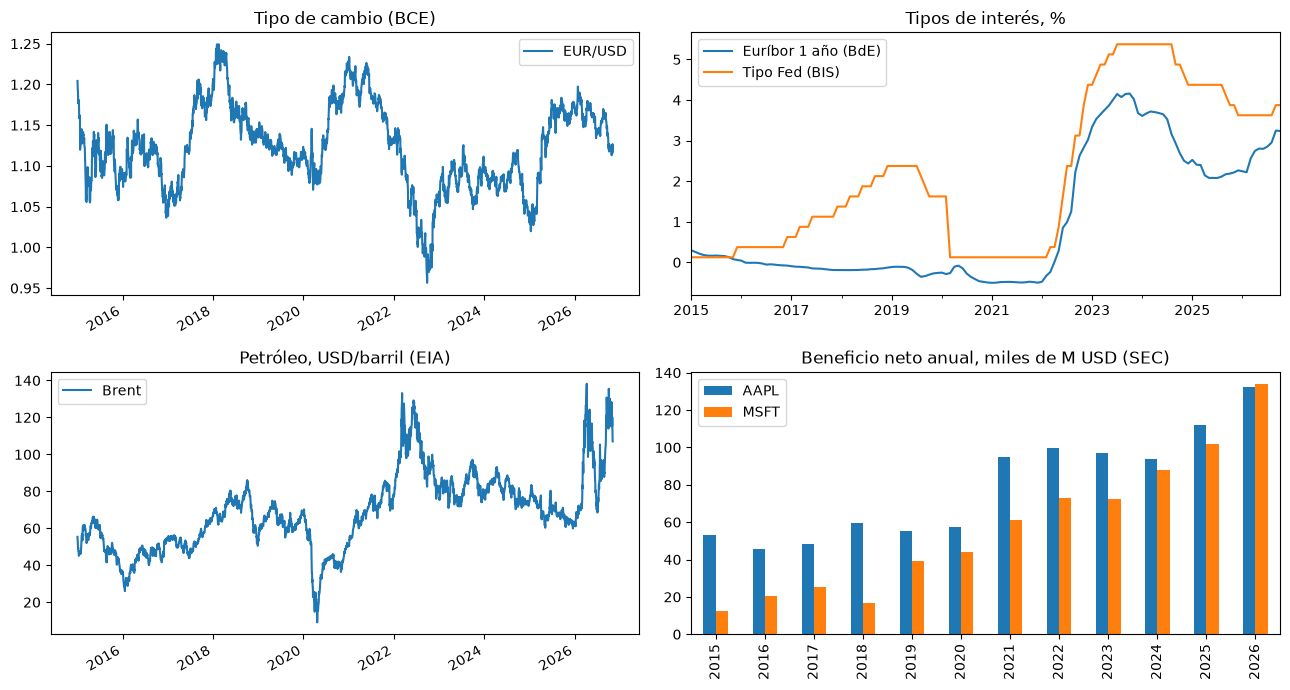

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
panels = [
    (axes[0, 0], {"EXR/D.USD.EUR.SP00.A": "EUR/USD"}, "Tipo de cambio (BCE)", None),
    (axes[0, 1], {"D_1NBAF472": "Euríbor 1 año (BdE)", "WS_CBPOL/M.US": "Tipo Fed (BIS)"},
     "Tipos de interés, %", None),
    (axes[1, 0], {"PET.RBRTE.D": "Brent"}, "Petróleo, USD/barril (EIA)", None),
    (axes[1, 1], {"AAPL/NetIncomeLoss:FY": "AAPL", "MSFT/NetIncomeLoss:FY": "MSFT"},
     "Beneficio neto anual, miles de M USD (SEC)", 1e9),
]
for ax, labels, title, scale in panels:
    available = {label: macro[i].data for i, label in labels.items() if i in macro}
    if not available:
        ax.set_title(f"{title}: sin datos")
        continue
    frame = pd.concat(available, axis=1, sort=True)
    if scale:
        frame = (frame / scale).groupby(frame.index.year).last()
        frame.plot(ax=ax, kind="bar", title=title)
    else:
        frame.plot(ax=ax, title=title)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 5. FRED: última revisión frente a vintage

Muchas series macro se **revisan** después de publicarse. Con `as_of`, FRED (vía ALFRED)
devuelve los datos **tal como se conocían ese día**, que es lo que habría visto un
backtest honesto. Comparamos el IPC de EE. UU. de hoy con el publicado a 30/06/2015.
SEC EDGAR admite lo mismo para los fundamentales (`as_of` = fecha de presentación).

Vintage: 2015-06-30; última observación conocida entonces: 2015-05-01
Meses revisados: 53 de 65


,hoy,publicado_2015-06-30,revisión
date,,,
2015-01-01,234.747,234.677,0.070
2015-02-01,235.342,235.186,0.156
2015-03-01,235.976,235.740,0.236
2015-04-01,236.222,235.982,0.240
2015-05-01,237.001,237.031,-0.030


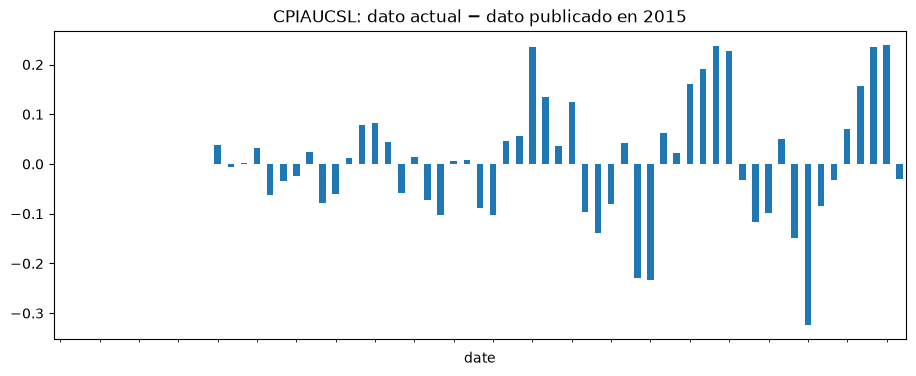

In [8]:
if os.getenv("FRED_API_KEY"):
    fred = build_download_service(None, "fred")
    request = dict(series_ids=["CPIAUCSL"], start=date(2010, 1, 1), end=date(2015, 6, 30))
    latest = fred.download_macro(MacroRequest(**request)).series["CPIAUCSL"]
    vintage = fred.download_macro(MacroRequest(**request, as_of=date(2015, 6, 30))).series[
        "CPIAUCSL"
    ]

    compare = pd.concat({"hoy": latest.data, "publicado_2015-06-30": vintage.data}, axis=1).dropna()
    compare["revisión"] = compare["hoy"] - compare["publicado_2015-06-30"]
    print(f"Vintage: {vintage.vintage}; última observación conocida entonces: {vintage.end}")
    print(f"Meses revisados: {(compare['revisión'].abs() > 1e-9).sum()} de {len(compare)}")
    display(compare.tail())
    compare["revisión"].plot(kind="bar", title="CPIAUCSL: dato actual − dato publicado en 2015")
    plt.xticks([])
    plt.show()
else:
    print("Sin FRED_API_KEY en .env: se omite esta sección.")

## 6. Documentos regulatorios

CNMV y ESMA no publican series sino documentos, así que tienen su propio modelo
(`RegulatoryDocument`) y su propio caso de uso. El RSS de la CNMV solo incluye lo
publicado desde la sesión anterior; ESMA lista los ficheros FIRDS.

In [9]:
def documents_table(source: str, request: DocumentRequest) -> pd.DataFrame:
    try:
        docs = build_document_service(source).list_documents(request)
    except ToolkitError as exc:
        print(f"{source}: {exc}")
        return pd.DataFrame()
    print(f"{source}: {len(docs)} documentos")
    return pd.DataFrame(
        [
            {
                "publicado": d.published_at,
                "id": d.identifier,
                "emisor / tipo": d.issuer or d.category,
                "título": d.title,
            }
            for d in docs
        ]
    )


display(documents_table("cnmv", DocumentRequest(limit=5)))
documents_table("esma", DocumentRequest("DLTINS", limit=5))

cnmv: 2 documentos


,publicado,id,emisor / tipo,título
0,2026-11-06 17:14:44,43537,"AMPER, S.A.","AMPER, S.A.: Sobre instrumentos financieros"
1,2026-11-06 17:02:04,43536,"TECNICAS REUNIDAS, S.A.","TECNICAS REUNIDAS, S.A.: Programas de recompra..."


esma: 5 documentos


,publicado,id,emisor / tipo,título
0,2026-11-08,119880,DLTINS,DLTINS_20261108_01of01.zip
1,2026-11-07,119827,DLTINS,DLTINS_20261107_01of04.zip
2,2026-11-07,119828,DLTINS,DLTINS_20261107_02of04.zip
3,2026-11-07,119829,DLTINS,DLTINS_20261107_03of04.zip
4,2026-11-07,119830,DLTINS,DLTINS_20261107_04of04.zip


## 7. Validación de inputs

¿Debería el toolkit aceptar cualquier cosa que contenga una serie de precios? **No**:
es **estricto en el núcleo y flexible en los adaptadores**. Las peticiones, las series y
la cartera validan un esquema cerrado al crearse. Así un dato mal formado falla pronto
y con un mensaje claro, en vez de producir un Sharpe o un VaR silenciosamente erróneo.
La flexibilidad está en los adaptadores, que traducen cada API a ese esquema (la
justificación completa está en el README).

Lo que es válido pero arriesgado no se rechaza: genera un **aviso**. Es el caso de los
huecos y `NaN` (sección 8) o de las divisas mezcladas.

In [10]:
raw = prices["AAPL"].data
usd, eur = prices["AAPL"], prices["^IBEX"]


def series_from(data: pd.DataFrame) -> PriceSeries:
    return PriceSeries("CSV", None, AssetType.EQUITY, "csv", "USD", Frequency.DAILY, data)


print("Peticiones")
try_build("lista de tickers vacía", lambda: DownloadRequest(tickers=[]))
try_build(
    "start > end",
    lambda: DownloadRequest(tickers=["AAPL"], start=date(2024, 2, 1), end=date(2024, 1, 1)),
)
try_build("límite de documentos 0", lambda: DocumentRequest(limit=0))

print("\nSeries de precios")
renamed = raw.rename(columns={"close": "precio"})
try_build("columna desconocida ('precio')", lambda: series_from(renamed))
try_build("fechas desordenadas", lambda: series_from(raw.iloc[::-1]))
try_build("fechas con zona horaria", lambda: series_from(raw.tz_localize("UTC")))
try_build("precios como texto", lambda: series_from(raw.astype({"close": str})))

print("\nCartera")
try_build("pesos que suman 0,9", lambda: Portfolio([usd], {"AAPL": 0.9}))
try_build("peso negativo", lambda: Portfolio([usd, eur], {"AAPL": 1.2, "^IBEX": -0.2}))
try_build("ticker sin serie", lambda: Portfolio([usd], {"AAPL": 0.5, "MSFT": 0.5}))
try_build("USD + EUR (por defecto)", lambda: Portfolio([usd, eur], {"AAPL": 0.5, "^IBEX": 0.5}))
try_build(
    "USD + EUR con strict_currency=True",
    lambda: Portfolio([usd, eur], {"AAPL": 0.5, "^IBEX": 0.5}, strict_currency=True),
)

Peticiones
lista de tickers vacía             → InvalidRequestError: tickers no puede estar vacío
start > end                        → InvalidRequestError: start (2024-02-01) no puede ser posterior a end (2024-01-01)
límite de documentos 0             → InvalidRequestError: limit debe ser >= 1 (recibido 0)

Series de precios
columna desconocida ('precio')     → InvalidSeriesError: CSV: faltan columnas obligatorias ['close']
fechas desordenadas                → InvalidSeriesError: CSV: el índice no está ordenado de forma creciente
fechas con zona horaria            → InvalidSeriesError: CSV: el índice debe ser tz-naive (tiene tz=UTC)
precios como texto                 → InvalidSeriesError: CSV: columnas no numéricas ['close']

Cartera
pesos que suman 0,9                → InvalidSeriesError: Portfolio: los pesos suman 0.900000, deben sumar 1
peso negativo                      → InvalidSeriesError: Portfolio: no se admiten pesos negativos
ticker sin serie                   → InvalidSeries

## 8. Limpieza y alineación de calendarios

Una cartera combina activos con **calendarios distintos**: AAPL cotiza en días hábiles
de EE. UU., el IBEX 35 sigue los festivos españoles y bitcoin cotiza 24/7. En la unión
de calendarios aparecen huecos (`NaN`):

In [11]:
recent = {
    **market.download_prices(DownloadRequest(tickers=["AAPL"], start=date(2026, 1, 1))).series,
    **market.download_prices(
        DownloadRequest(tickers=["^IBEX"], start=date(2026, 1, 1), asset_type=AssetType.INDEX)
    ).series,
    **crypto.series,
}
union = pd.DataFrame({t: s.prices for t, s in recent.items()})
print("Observaciones por activo:", {t: s.n_obs for t, s in recent.items()})
union.loc["2026-01-01":"2026-01-12"].round(1)

Observaciones por activo: {'AAPL': 214, '^IBEX': 218, 'bitcoin': 312}


,AAPL,^IBEX,bitcoin
date,,,
2026-01-01,NaN,NaN,87575.0
2026-01-02,270.3,17492.4,88764.1
2026-01-03,NaN,NaN,89978.9
2026-01-04,NaN,NaN,90614.4
2026-01-05,266.5,17614.4,91879.6
2026-01-06,261.6,17647.1,93879.9
2026-01-07,259.6,17596.4,93649.6
2026-01-08,258.3,17654.7,91286.0
2026-01-09,258.7,17649.0,91027.7


`Portfolio` **alinea primero los precios** (`toolkit.domain.cleaning.align_prices`) y
solo después calcula los retornos. El orden importa. Si se calculan los retornos de cada
serie y luego se cruzan por fecha, el retorno de bitcoin del lunes es domingo→lunes,
mientras que el de AAPL es viernes→lunes. Además, el movimiento del fin de semana se
pierde. La tabla compara los lunes con los dos métodos:

In [12]:
if len(recent) < 3:
    print("Falta alguna serie (ver errores arriba): se omite la comparación.")
else:
    weights3 = {"AAPL": 0.4, "^IBEX": 0.4, "bitcoin": 0.2}
    mixed = Portfolio(list(recent.values()), weights3)

    # Método ingenuo: retornos por serie y cruce de fechas después (lo que NO se hace)
    naive = pd.concat({t: s.returns for t, s in recent.items()}, axis=1, join="inner")
    mondays = mixed.returns.index[mixed.returns.index.day_of_week == 0][:5]
    comparison = pd.DataFrame(
        {
            "BTC ingenuo (dom→lun)": naive["bitcoin"].reindex(mondays),
            "BTC alineado (vie→lun)": mixed.returns["bitcoin"].reindex(mondays),
            "AAPL (vie→lun)": mixed.returns["AAPL"].reindex(mondays),
        }
    )
    display(fmt(comparison, dict.fromkeys(comparison.columns, "{:+.2%}")))

,BTC ingenuo (dom→lun),BTC alineado (vie→lun),AAPL (vie→lun)
date,,,
2026-01-05,+1.40%,+3.51%,-1.38%
2026-01-12,+0.48%,-0.19%,+0.34%
2026-01-26,-2.83%,-3.19%,+2.97%
2026-02-02,-2.23%,-9.14%,+4.06%
2026-02-09,+1.66%,+12.14%,-1.17%


Hay dos métodos de alineación:

- **`inner`** (por defecto): solo las fechas comunes. Cada retorno es comparable entre
  activos.
- **`ffill`**: conserva la unión rellenando hacia delante como mucho `ffill_limit`
  periodos. Nunca rellena hacia atrás (*look-ahead*), pero cada relleno es un retorno 0
  artificial que **reduce** la volatilidad medida.

La anualización usa el calendario resultante: 252 sesiones si solo hay días hábiles y
365 si quedan fines de semana.

In [13]:
if len(recent) == 3:
    rows = {}
    for method in ["inner", "ffill"]:
        pf = Portfolio(list(recent.values()), weights3, alignment=method, ffill_limit=3)
        report = pf.alignment_report
        rows[method] = {
            "fechas en la unión": report.n_union,
            "fechas conservadas": report.n_kept,
            "descartadas": report.n_dropped,
            "rellenadas": sum(report.filled_by_ticker.values()),
            "periodos/año": pf.periods_per_year,
            "volatilidad anual": metrics.annualized_volatility(
                pf.portfolio_returns, pf.periods_per_year
            ),
        }
    table = pd.DataFrame(rows).T
    counts = [c for c in table.columns if c != "volatilidad anual"]
    display(fmt(table, {"volatilidad anual": "{:.2%}"} | dict.fromkeys(counts, "{:.0f}")))

    # Lo que se ha descartado y los avisos quedan en el informe (aquí solo dos secciones)
    display(Markdown(mixed.report(sections=["diagnostico", "advertencias"], title="Cartera mixta")))

,fechas en la unión,fechas conservadas,descartadas,rellenadas,periodos/año,volatilidad anual
inner,312,212,100,0,252,17.08%
ffill,312,308,4,185,365,16.95%


# Cartera mixta

## Diagnóstico de datos

- **Método de alineación:** `inner`
- **Fechas en la unión de calendarios:** 312
- **Fechas conservadas:** 212
- **Fechas descartadas:** 100 (32.1%)
  - 2026-01-01, 2026-01-03, 2026-01-04, 2026-01-10, 2026-01-11, 2026-01-17, 2026-01-18, 2026-01-19, 2026-01-24, 2026-01-25 y 90 más

| Activo | Observaciones | Sin precio en la unión | NaN eliminados | Rellenados |
| :--- | ---: | ---: | ---: | ---: |
| AAPL | 214 | 98 | 0 | 0 |
| ^IBEX | 218 | 94 | 0 | 0 |
| bitcoin | 312 | 0 | 0 | 0 |

## Advertencias de riesgo

- ⚠️ Divisas mezcladas (EUR, USD): los retornos están en moneda local y no incluyen el efecto del tipo de cambio.
- ⚠️ Muestra corta: 211 retornos (< 252); las métricas son poco fiables.
- ⚠️ La alineación descartó 100 de 312 fechas (32%): revisa calendarios o huecos.


## 9. Cartera: métricas y gráficos

`Portfolio` es una *dataclass* que agrega varias `PriceSeries` con sus pesos. La
cartera de ejemplo combina activos con papeles distintos para que la diversificación
se vea en los resultados:

| Activo | Peso | Papel |
|---|---|---|
| AAPL, MSFT | 20 % cada una | renta variable tecnológica |
| XLE | 15 % | energía: cíclica y ligada a la inflación |
| IEF | 25 % | bonos del Tesoro de EE. UU. a 7-10 años |
| GLD | 20 % | oro: activo real |

Los pesos se fijan por el papel de cada activo, no optimizando sobre estos datos. Todos
cotizan en USD en EE. UU., así que no hay avisos de divisa ni fechas descartadas (la
alineación ya se vio en la sección 8).

In [14]:
diversifiers = market.download_prices(
    DownloadRequest(tickers=["XLE", "IEF", "GLD"], start=START, end=END)  # ETFs: tipo equity
)
show_errors(diversifiers)
prices |= diversifiers.series

weights = {"AAPL": 0.20, "MSFT": 0.20, "XLE": 0.15, "IEF": 0.25, "GLD": 0.20}
portfolio = Portfolio(series=[prices[t] for t in weights], weights=weights)

ppy = portfolio.periods_per_year
r = portfolio.portfolio_returns
print(f"{len(r)} retornos diarios, {portfolio.returns.index[0].date()} → {r.index[-1].date()}")
print(f"Retorno anualizado: {metrics.annualized_return(r, ppy):.1%}")
print(f"Volatilidad anual:  {metrics.annualized_volatility(r, ppy):.1%}")
print(f"Máximo drawdown:    {metrics.max_drawdown(r):.1%}")

3 OK, 0 fallidas
1254 retornos diarios, 2021-01-05 → 2025-12-31
Retorno anualizado: 14.8%
Volatilidad anual:  12.4%
Máximo drawdown:    -14.9%


`plots_report()` reúne las visualizaciones de la cartera: rendimiento comparado
(base 100), evolución del valor, drawdown, matriz de correlación, pesos y
riesgo/retorno. El dominio prepara los datos y el dibujo lo hace el renderer de
matplotlib registrado por `bootstrap.configure_plotting()`, así que el núcleo no
depende de matplotlib.

La matriz de correlación muestra que bonos, oro y energía apenas se mueven con las dos
tecnológicas. Por eso la cartera queda a la izquierda de todos sus activos de renta
variable en el gráfico de riesgo/retorno: menos volatilidad que cualquiera de ellos.

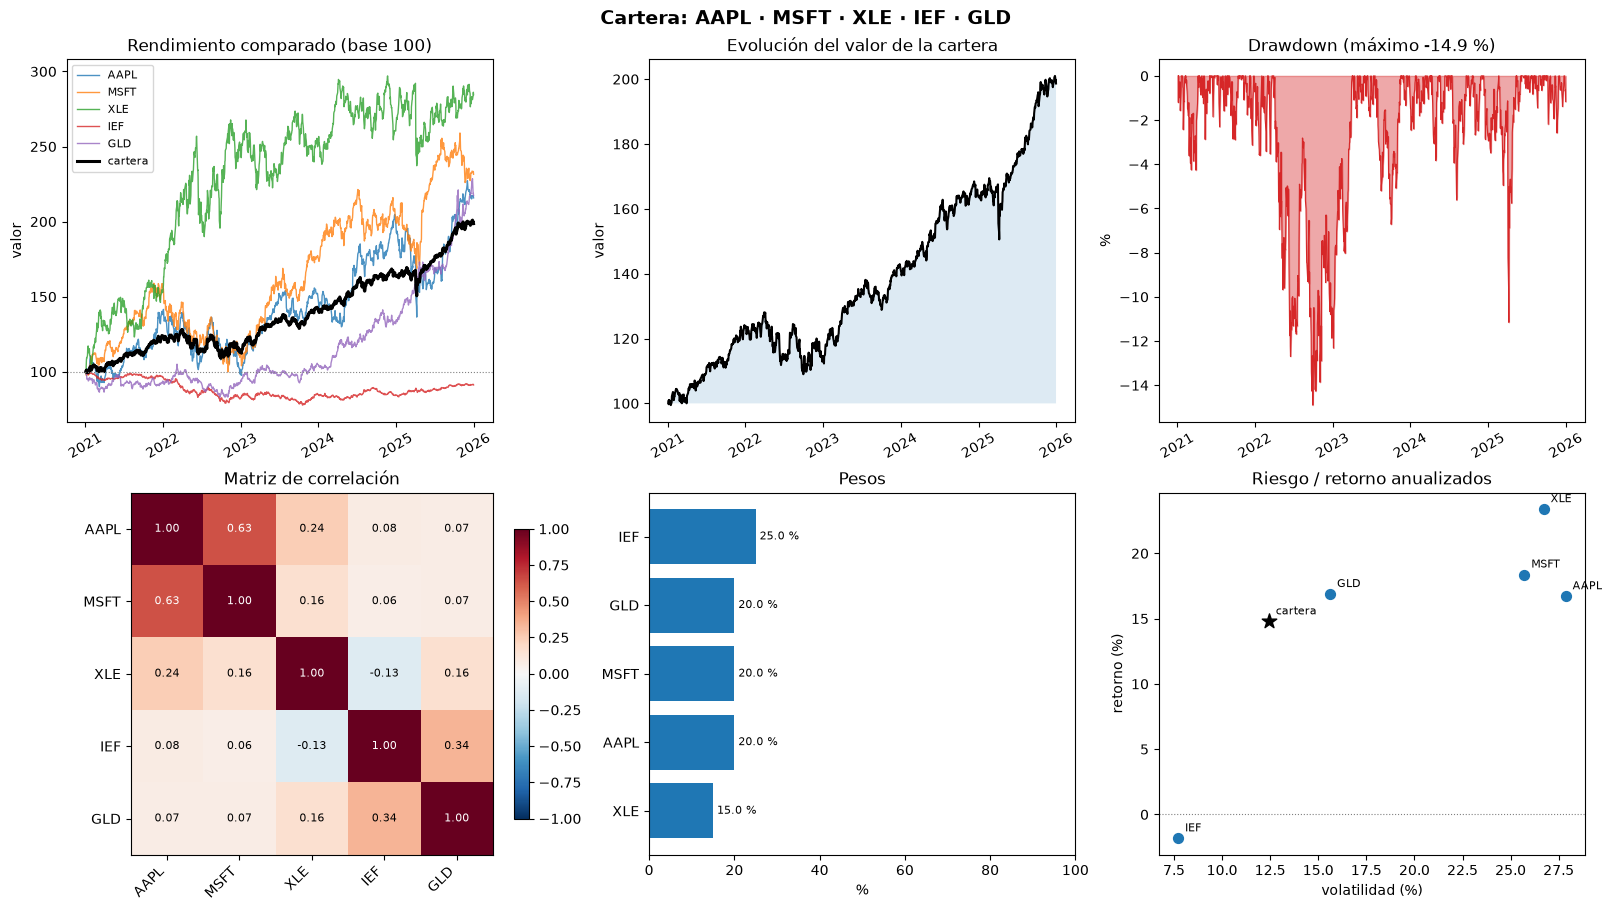

In [15]:
portfolio.plots_report(title="Cartera: AAPL · MSFT · XLE · IEF · GLD")

## 10. Monte Carlo

`monte_carlo()` es un método de la cartera y simula su valor con un movimiento
browniano geométrico. Todo es parametrizable: iteraciones (`n_simulations`), horizonte
(`n_steps`), retorno (`mu`), volatilidad (`sigma`) y semilla. Si no se indican `mu` y
`sigma`, se estiman de los retornos alineados. `monte_carlo_asset()` aplica lo mismo a
un único activo, partiendo de su último precio.

Comparamos tres escenarios a un año. Para cada uno se muestran dos medidas de riesgo de
cola:

- **VaR 95 %**: la pérdida que solo se supera en el 5 % de los escenarios. Es el
  estándar, pero no dice cuánto se pierde cuando se supera.
- **CVaR 95 %** (*Expected Shortfall*): la pérdida **media** en ese 5 % peor. Mira
  dentro de la cola, y por eso Basilea (FRTB) lo usa en lugar del VaR.

Ambas salen de un modelo con retornos normales, μ y σ constantes: infravaloran las
colas gruesas reales, de ahí el escenario de estrés.

In [16]:
sim = portfolio.monte_carlo(n_steps=252, n_simulations=5000, seed=42)  # estimado
stress = portfolio.monte_carlo(  # estrés: sin rentabilidad esperada y el doble de volatilidad
    n_steps=252, n_simulations=5000, mu=0.0, sigma=2 * portfolio.volatility, seed=42
)
sim_aapl = portfolio.monte_carlo_asset("AAPL", n_steps=252, n_simulations=5000, seed=7)

scenarios = {"cartera (estimado)": sim, "cartera (estrés)": stress, "AAPL (estimado)": sim_aapl}
table = pd.DataFrame(
    {
        name: {
            "μ diario": s.mu,
            "σ diaria": s.sigma,
            "valor inicial": s.initial_value,
            "mediana final": s.quantile(0.5),
            "percentil 5": s.quantile(0.05),
            "VaR 95 %": s.var(0.95),
            "CVaR 95 %": s.cvar(0.95),
            "P(pérdida)": s.prob_loss,
        }
        for name, s in scenarios.items()
    }
).T
two_decimals = ["valor inicial", "mediana final", "percentil 5", "VaR 95 %", "CVaR 95 %"]
fmt(table, {"μ diario": "{:.5f}", "σ diaria": "{:.4f}", "P(pérdida)": "{:.1%}"}
    | dict.fromkeys(two_decimals, "{:.2f}"))

,μ diario,σ diaria,valor inicial,mediana final,percentil 5,VaR 95 %,CVaR 95 %,P(pérdida)
cartera (estimado),0.00058,0.0078,100.00,114.85,93.58,6.42,11.01,13.7%
cartera (estrés),0.00000,0.0157,100.00,97.06,64.43,35.57,41.60,54.4%
AAPL (estimado),0.00077,0.0176,271.12,315.57,199.58,71.54,90.31,29.6%


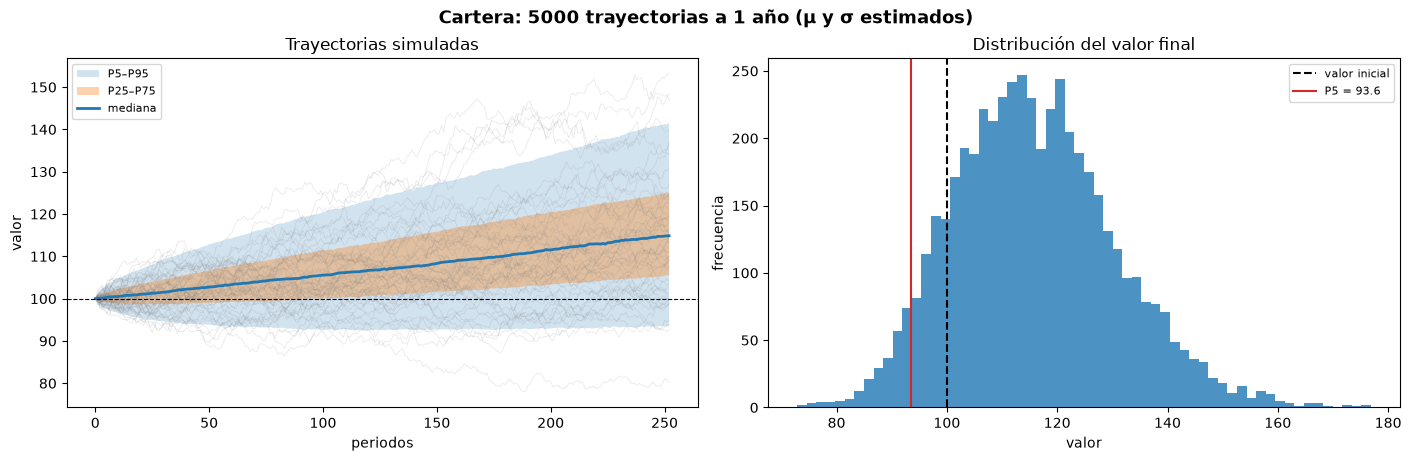

In [17]:
sim.plot(title="Cartera: 5000 trayectorias a 1 año (μ y σ estimados)")

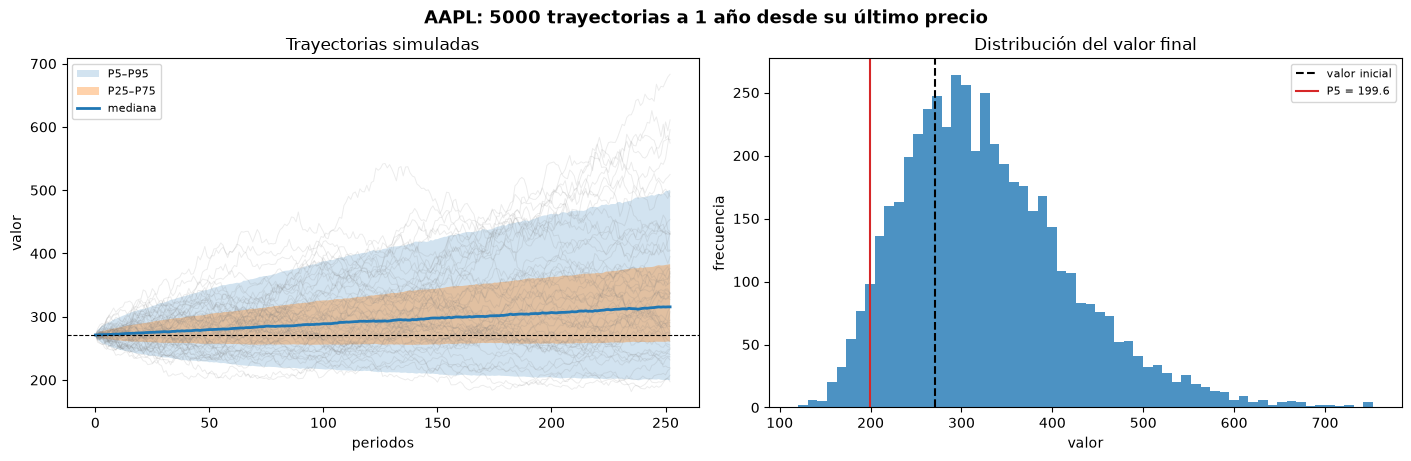

In [18]:
sim_aapl.plot(title="AAPL: 5000 trayectorias a 1 año desde su último precio")

## 11. Informe de la cartera en Markdown

`report()` genera texto Markdown estructurado y **parametrizable**. Se puede elegir:

- el tipo libre de riesgo del Sharpe;
- el nivel de confianza del VaR y del CVaR;
- las secciones que se incluyen (en la sección 8 se usaron solo dos);
- la simulación que se resume;
- los umbrales de las advertencias de riesgo.

Aquí se genera completo, con la simulación de estrés y umbrales más exigentes que los
de por defecto: con `high_corr=0.60`, la correlación entre AAPL y MSFT (0,63) genera un
aviso que con el umbral por defecto (0,80) no aparecería.

En la tabla de activos, fíjate en XLE y MSFT: tienen prácticamente el mismo VaR 99 %
(≈ 4 % diario), pero el CVaR de XLE es claramente mayor. Cuando la energía tiene un mal
día, lo tiene peor. El VaR no lo ve; el CVaR, sí.

In [19]:
informe = portfolio.report(
    risk_free=0.03,
    confidence=0.99,
    simulation=stress,
    thresholds=RiskThresholds(max_weight=0.40, high_corr=0.60),
    title="Informe de cartera: AAPL · MSFT · XLE · IEF · GLD",
)
display(Markdown(informe))

# Informe de cartera: AAPL · MSFT · XLE · IEF · GLD

## Resumen

- **Activos:** 5 (AAPL, MSFT, XLE, IEF, GLD)
- **Periodo:** 2021-01-05 → 2025-12-31
- **Retornos:** 1254 (daily, 252 periodos/año)
- **Fuentes:** yahoo · **Divisas:** USD
- **Alineación:** `inner`

## Métricas de la cartera

| Métrica | Valor |
| :--- | ---: |
| Retorno anualizado (CAGR) | 14.79% |
| Volatilidad anualizada | 12.43% |
| Sharpe (rf = 3.00%) | 0.93 |
| Máximo drawdown | -14.90% |
| VaR histórico 99% (1 periodo) | 2.08% |
| CVaR histórico 99% (1 periodo) | 2.63% |
| Retorno medio por periodo | 0.0578% |
| Volatilidad por periodo | 0.7831% |

_Pesos constantes: la cartera se rebalancea a sus pesos objetivo cada periodo._

## Pesos

| Activo | Peso |
| :--- | ---: |
| AAPL | 20.0% |
| MSFT | 20.0% |
| XLE | 15.0% |
| IEF | 25.0% |
| GLD | 20.0% |

## Activos

| Activo | Retorno anual | Volatilidad anual | Sharpe | Máx. drawdown | VaR | CVaR |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| AAPL | 16.72% | 27.86% | 0.59 | -33.36% | 4.24% | 5.55% |
| MSFT | 18.38% | 25.71% | 0.67 | -37.15% | 4.02% | 5.00% |
| XLE | 23.39% | 26.72% | 0.81 | -26.04% | 4.01% | 6.01% |
| IEF | -1.83% | 7.72% | -0.58 | -22.23% | 1.19% | 1.40% |
| GLD | 16.88% | 15.62% | 0.89 | -21.03% | 2.48% | 3.31% |

_Calculado sobre la muestra alineada de la cartera; puede diferir de los estadísticos de cada `PriceSeries`, que usan su serie completa._

## Correlaciones

|  | AAPL | MSFT | XLE | IEF | GLD |
| :--- | ---: | ---: | ---: | ---: | ---: |
| AAPL | 1.00 | 0.63 | 0.24 | 0.08 | 0.07 |
| MSFT | 0.63 | 1.00 | 0.16 | 0.06 | 0.07 |
| XLE | 0.24 | 0.16 | 1.00 | -0.13 | 0.16 |
| IEF | 0.08 | 0.06 | -0.13 | 1.00 | 0.34 |
| GLD | 0.07 | 0.07 | 0.16 | 0.34 | 1.00 |

## Diagnóstico de datos

- **Método de alineación:** `inner`
- **Fechas en la unión de calendarios:** 1255
- **Fechas conservadas:** 1255
- **Fechas descartadas:** 0 (0.0%)

| Activo | Observaciones | Sin precio en la unión | NaN eliminados | Rellenados |
| :--- | ---: | ---: | ---: | ---: |
| AAPL | 1255 | 0 | 0 | 0 |
| MSFT | 1255 | 0 | 0 | 0 |
| XLE | 1255 | 0 | 0 | 0 |
| IEF | 1255 | 0 | 0 | 0 |
| GLD | 1255 | 0 | 0 | 0 |

## Simulación de Monte Carlo

| Resultado | Valor |
| :--- | ---: |
| Horizonte (periodos) | 252 |
| Trayectorias | 5000 |
| μ / σ por periodo | 0.00000 / 0.01566 |
| Valor inicial | 100.00 |
| Mediana del valor final | 97.06 |
| Percentil 1% del valor final | 54.80 |
| VaR 99% al horizonte | 45.20 |
| CVaR 99% al horizonte (pérdida media en la cola) | 50.21 |
| Probabilidad de pérdida | 54.4% |

_Movimiento browniano geométrico con μ y σ constantes: no recoge colas gruesas ni cambios de régimen._

## Advertencias de riesgo

- ⚠️ Correlación alta entre AAPL y MSFT (0.63): diversificación limitada.


## 12. Guardar las series y usar la CLI

`StoreSeries` guarda cada serie en un fichero. El notebook no sabe cómo se escriben: si
mañana el destino fuera una base de datos, solo cambiaría `build_storage_service`. El
informe es texto, así que se guarda directamente como `.md`.

In [20]:
out_dir = Path(tempfile.mkdtemp(prefix="toolkit_demo_"))
saved = build_storage_service(out_dir, "csv").store(prices)
saved += build_storage_service(out_dir / "macro", "csv").store(macro)
(out_dir / "informe_cartera.md").write_text(informe, encoding="utf-8")
print(f"{len(saved)} series y 1 informe guardados en {out_dir.name}/")

# Releer y comprobar que el fichero conserva la serie
reloaded = pd.read_csv(out_dir / "AAPL.csv", index_col="date", parse_dates=True)
pd.testing.assert_frame_equal(
    reloaded, prices["AAPL"].data, check_freq=False, check_index_type=False
)
print("AAPL.csv releído: idéntico a la PriceSeries original ✓")

17 series y 1 informe guardados en toolkit_demo_h15saj3m/
AAPL.csv releído: idéntico a la PriceSeries original ✓


La CLI es otro adaptador de entrada sobre los mismos casos de uso
(`python -m toolkit` equivale al comando `toolkit`):

In [21]:
cli_dir = out_dir / "cli"
command = [
    sys.executable, "-m", "toolkit", "prices", "^GSPC", "^IBEX", "NOEXISTE123",
    "--type", "index", "--start", "2025-01-01", "--end", "2025-12-31", "--out", str(cli_dir),
]
completed = subprocess.run(command, capture_output=True, text=True, encoding="utf-8")
print(completed.stdout.replace(str(out_dir), "<out_dir>"))
print("código de salida:", completed.returncode, "(0 = al menos una serie OK)")

Descargadas: 2 OK, 1 fallidas
ticker      fuente        divisa   n_obs  inicio     fin           media_ret    std_ret
^GSPC       yahoo         USD        250  2025-01-02 2025-12-31     0.000688   0.011835
^IBEX       yahoo         EUR        255  2025-01-02 2025-12-31     0.001603   0.010173
Errores:
  NOEXISTE123: yahoo: sin datos para NOEXISTE123 en el rango solicitado
  guardado: <out_dir>\cli\_GSPC.csv
  guardado: <out_dir>\cli\_IBEX.csv

código de salida: 0 (0 = al menos una serie OK)


## Resumen

| Capacidad | Dónde |
|---|---|
| Acciones e índices en lote; un fallo no aborta el lote | §2 |
| Misma `PriceSeries` desde Yahoo, Twelve Data, Alpha Vantage o CoinGecko | §2, §3 |
| Macro, fiscal, materias primas y fundamentales como `MacroSeries` | §4 |
| Datos *point-in-time* (vintages de FRED/ALFRED) | §5 |
| Documentos regulatorios (CNMV, ESMA) | §6 |
| Validación de peticiones, series y cartera | §7 |
| Limpieza de `NaN` y alineación de calendarios (`inner` / `ffill`) | §8 |
| `Portfolio` diversificada con estadísticos y `plots_report()` | §9 |
| Monte Carlo parametrizable para cartera y activo, con `plot()` | §10 |
| `report()` en Markdown con métricas, diagnósticos y advertencias | §8, §11 |
| Persistencia y CLI sobre los mismos casos de uso | §12 |

Ninguna celda importa un adaptador concreto: todo pasa por `bootstrap`. La arquitectura
completa, con los diagramas de clases, está en
[`docs/architecture.md`](../docs/architecture.md).